# 03 - Injection gallery: 15 types x {naive, consistent}

Companion notebook to `results/figures/injection_*.png`. It runs the seeded
injector once and plots one example per type, showing that **consistent** edits
keep the electrical identities while **naive** single-channel edits break them
(hypothesis H1).

Prerequisites: `python -m energymind.io` and `python -m energymind.clean`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from energymind import clean, inject, inject_plots as G, io
from energymind.config import load_settings

warnings.filterwarnings("ignore", category=FutureWarning)
%config InlineBackend.figure_format = "png"
plt.rcParams["figure.dpi"] = 110

PREVALENCE, SEED = 0.05, 1
settings = load_settings()
baseline = clean.load_baseline(settings)
injected, labels = inject.inject_all(baseline, settings, PREVALENCE, SEED)
FIG = io.resolve("results/figures")
print(f"baseline {baseline.shape}, injected {injected.shape}, {len(labels)} events -> {FIG}")

baseline (227760, 54), injected (227760, 54), 290 events -> C:\Users\aming\OneDrive\Desktop\tsyp\EnergyMind\results\figures


## Labels at a glance (computed)

In [2]:
summary = (
    labels.groupby(["origin", "type", "variant"])
    .agg(events=("anomaly_id", "size"), median_severity=("severity", lambda s: s.mode().iat[0]))
    .reset_index()
)
summary.style.hide(axis="index")

origin,type,variant,events,median_severity
adversarial,mimicry,consistent,4,low
adversarial,replay,consistent,10,low
adversarial,under_reporting,consistent,2,low
data_quality,additive_bias,consistent,2,low
data_quality,additive_bias,naive,2,low
data_quality,dead_sensor,naive,34,medium
data_quality,dropout,consistent,9,high
data_quality,dropout,naive,19,high
data_quality,gain_error,naive,4,low
data_quality,noise_burst,consistent,54,low


## Overview

Events by type and origin, the severity mix (effect size in sigma units), the
variant and scope split.

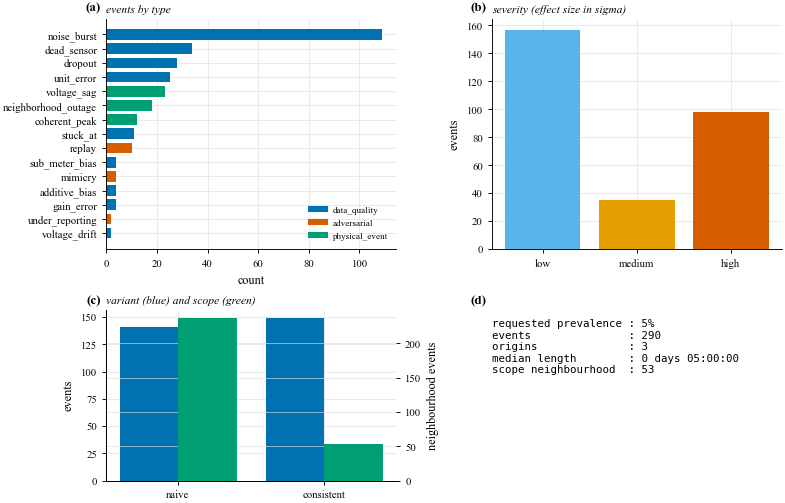

In [3]:
G.fig_injection_overview(labels, PREVALENCE, FIG)
plt.show()

## Active power: one example per type x variant

Baseline in grey, injected in the origin colour, event window shaded.

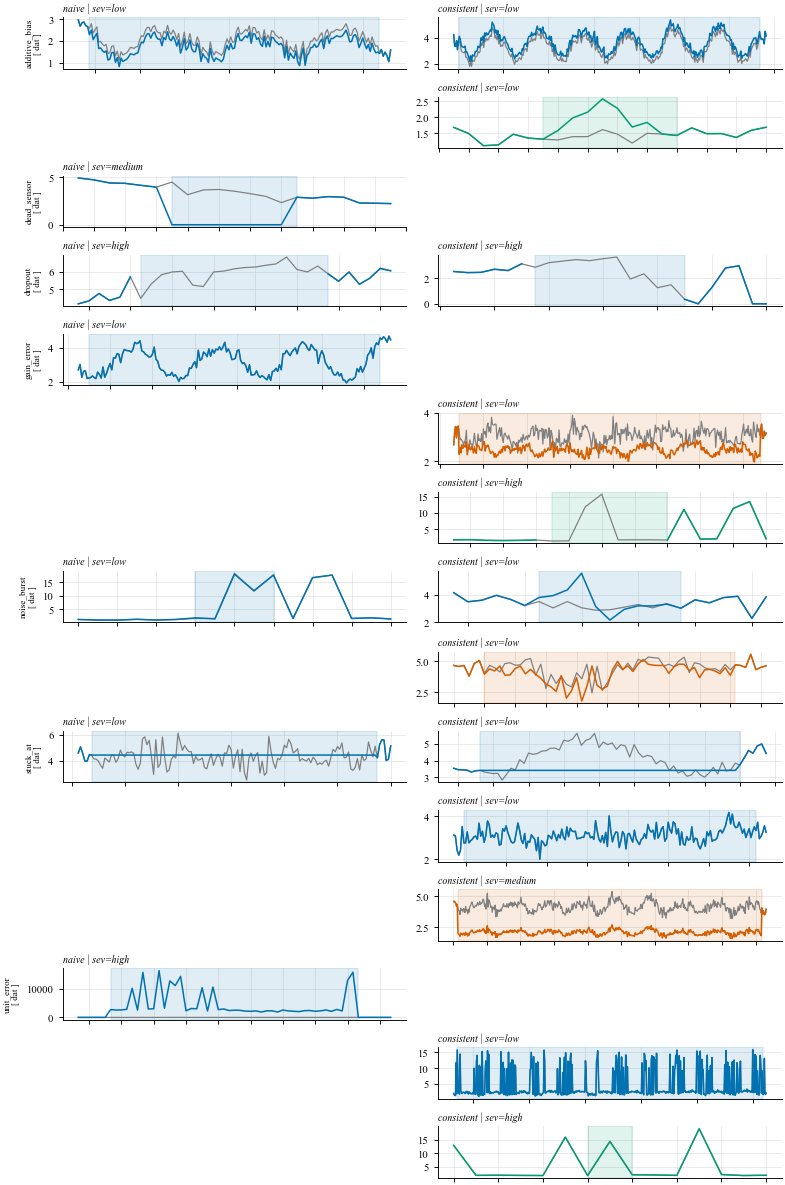

In [4]:
G.fig_type_gallery(baseline, injected, labels, FIG)
plt.show()

## Identity residual: naive breaks, consistent holds

The maximum absolute electrical-identity residual per interval (log scale), with
the 1e-2 tolerance. Consistent edits sit below the tolerance; naive edits shoot
far above it.

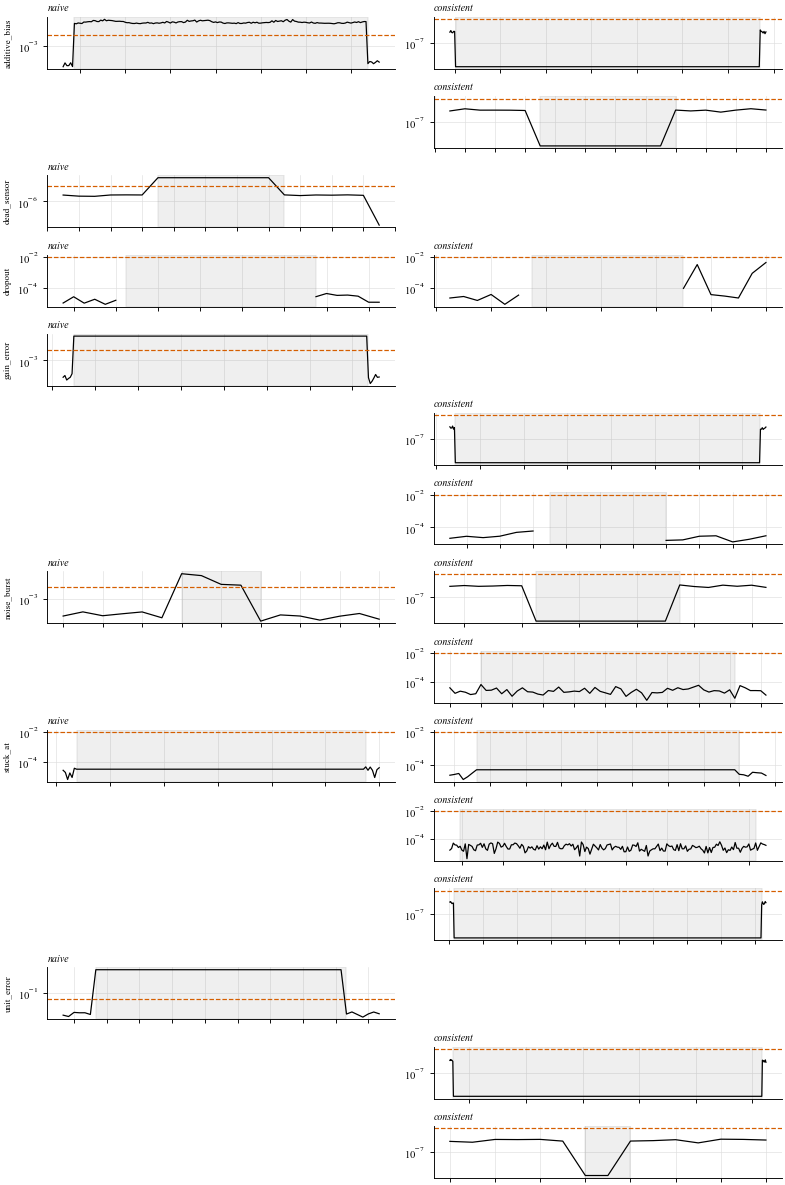

In [5]:
G.fig_residual_gallery(baseline, injected, labels, FIG)
plt.show()

## Detailed comparison for selected types

Active power, voltage and the identity residual for naive vs consistent.

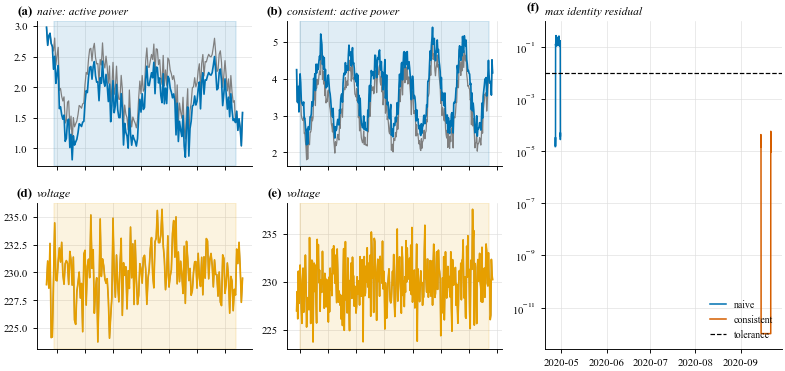

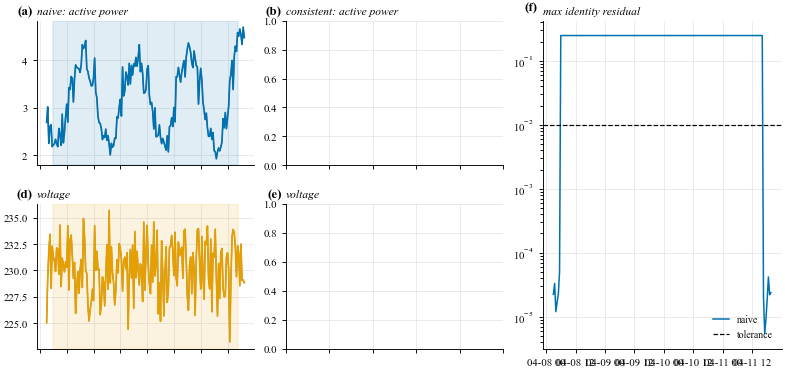

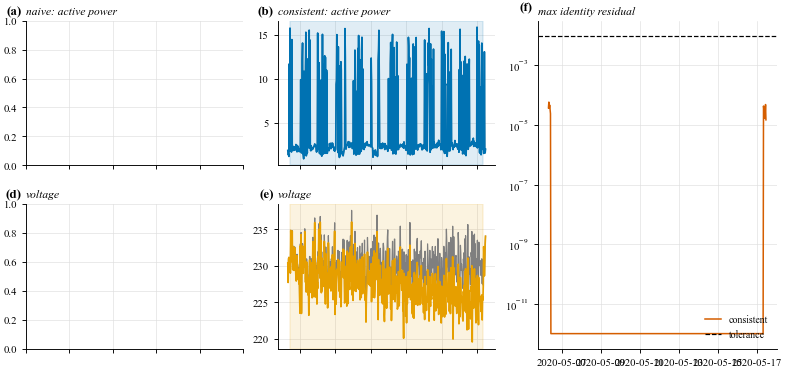

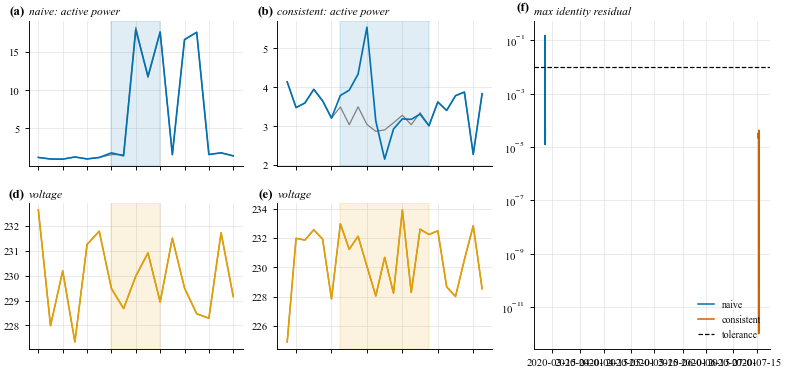

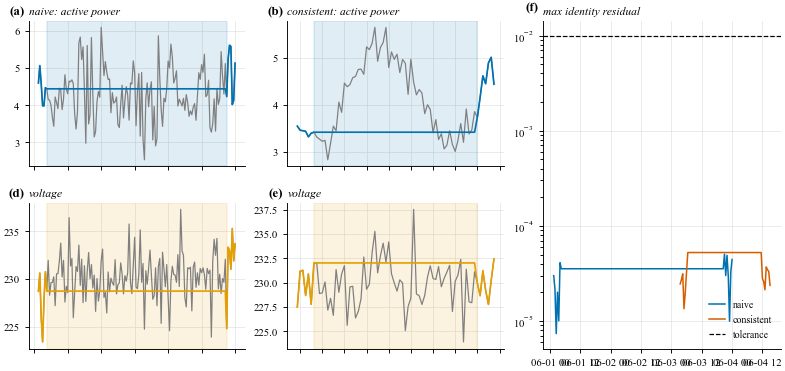

In [6]:
for name in ["additive_bias", "gain_error", "voltage_drift", "noise_burst", "stuck_at"]:
    if name in set(labels["type"]):
        G.fig_variant_comparison(baseline, injected, labels, name, FIG)
        plt.show()

## Label schema

One row per injected event, with everything needed for event-level evaluation.

In [7]:
labels.head(10)

,anomaly_id,household_id,t_start,t_end,type,origin,severity,variant,scope,params,seed,injector_version,provenance
0,24f694ea-f2d5-5425-99eb-704e866e2b69,HH_00055_AUS,2020-09-15 00:30:00+00:00,2020-09-21 17:00:00+00:00,additive_bias,data_quality,low,consistent,single,"{""effect_p_sigma"": 0.5, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
1,52f25cb4-eecc-52df-830e-2c676b448058,HH_00175_AUS,2020-04-26 22:30:00+00:00,2020-04-30 04:30:00+00:00,additive_bias,data_quality,low,naive,single,"{""effect_p_sigma"": 0.5, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
2,b4eeb1d4-be6f-5d01-b26e-12b412d9a3c7,HH_00055_AUS,2020-01-06 04:30:00+00:00,2020-01-10 21:00:00+00:00,additive_bias,data_quality,low,consistent,single,"{""effect_p_sigma"": 1.0, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
3,94a88899-05ab-53f3-a544-1c95f45444e1,HH_00092_AUS,2020-11-17 11:30:00+00:00,2020-11-22 21:00:00+00:00,additive_bias,data_quality,medium,naive,single,"{""effect_p_sigma"": 2.0, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
4,552abf5e-8a26-54fa-a128-9136678cfab2,HH_00055_AUS,2020-04-08 06:00:00+00:00,2020-04-11 16:30:00+00:00,gain_error,data_quality,low,naive,single,"{""effect_p_sigma"": 0.0, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
5,b9e09170-bee5-547a-80ff-edb1047a60aa,HH_00055_AUS,2020-05-09 06:00:00+00:00,2020-05-12 16:30:00+00:00,gain_error,data_quality,low,naive,single,"{""effect_p_sigma"": 0.0, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
6,a9473fe0-ff72-57c8-a9a4-430907e6a023,HH_00092_AUS,2020-06-07 19:30:00+00:00,2020-06-14 04:30:00+00:00,gain_error,data_quality,low,naive,single,"{""effect_p_sigma"": 0.0, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
7,2d6ffefb-bf75-57f0-ad06-3416c350c151,HH_00072_AUS,2020-06-20 07:00:00+00:00,2020-06-25 16:00:00+00:00,gain_error,data_quality,low,naive,single,"{""effect_p_sigma"": 0.0, ""effect_v_sigma"": 0.0,...",1,0.1.0,simulated
8,33938057-f82e-5b5a-a75e-871c116fbc5a,HH_00189_AUS,2020-05-06 10:30:00+00:00,2020-05-17 08:30:00+00:00,voltage_drift,data_quality,low,consistent,single,"{""d_v"": -5, ""effect_p_sigma"": 0.0, ""effect_v_s...",1,0.1.0,simulated
9,e9a9c315-3730-56db-bbd4-7bc42786068a,HH_00189_AUS,2020-07-22 19:00:00+00:00,2020-07-30 03:00:00+00:00,voltage_drift,data_quality,low,consistent,single,"{""d_v"": -2, ""effect_p_sigma"": 0.0, ""effect_v_s...",1,0.1.0,simulated
